In [1]:
!pip -q install kaggle mne eeglabio tensorflow scikit-learn pandas numpy scipy matplotlib seaborn

In [2]:
# CELL 1 — Windows path + Kaggle setup
import os
import shutil
from pathlib import Path

HOME = Path.home()   # usually C:\Users\U
DESKTOP = HOME / "Desktop"
WORK_ROOT = DESKTOP / "Shoili"

# Put your kaggle json here:
KAGGLE_JSON_SOURCE = WORK_ROOT / "kaggle (2).json"

# Kaggle expects this target:
KAGGLE_DIR = HOME / ".kaggle"
KAGGLE_JSON_TARGET = KAGGLE_DIR / "kaggle.json"

# All new folders/files will stay inside Desktop\Shoili
DOWNLOAD_BASE = WORK_ROOT / "openneuro_work"
ZIP_PATH = DOWNLOAD_BASE / "openneuro-ds004504.zip"
EXTRACT_DIR = DOWNLOAD_BASE / "openneuro_ds004504"
DATASET_ROOT = EXTRACT_DIR / "ds004504"
OUTPUT_ROOT = WORK_ROOT / "eeg_ad_hc_rebuild"

KAGGLE_DIR.mkdir(parents=True, exist_ok=True)
DOWNLOAD_BASE.mkdir(parents=True, exist_ok=True)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

if not KAGGLE_JSON_SOURCE.exists():
    raise FileNotFoundError(f"Kaggle JSON file not found: {KAGGLE_JSON_SOURCE}")

shutil.copy2(KAGGLE_JSON_SOURCE, KAGGLE_JSON_TARGET)

# Windows permission-friendly
try:
    os.chmod(KAGGLE_JSON_TARGET, 0o600)
except Exception:
    pass

print("kaggle.json configured at:", KAGGLE_JSON_TARGET)
print("Download folder:", DOWNLOAD_BASE)
print("Dataset root will be:", DATASET_ROOT)
print("Output root:", OUTPUT_ROOT)


kaggle.json configured at: C:\Users\U\.kaggle\kaggle.json
Download folder: C:\Users\U\Desktop\Shoili\openneuro_work
Dataset root will be: C:\Users\U\Desktop\Shoili\openneuro_work\openneuro_ds004504\ds004504
Output root: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild


In [3]:
# CELL 2 — Imports + config + GPU check
import os
import gc
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mne
import tensorflow as tf

from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.metrics import (
    confusion_matrix, f1_score, accuracy_score, roc_auc_score, roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import Model, layers, utils
from tensorflow.keras.callbacks import (
    CSVLogger, TerminateOnNaN, ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
)
from tensorflow.keras.constraints import max_norm

from IPython.display import display

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
tf.get_logger().setLevel("ERROR")
mne.set_log_level("ERROR")

SEED = 42

def set_all_seeds(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_all_seeds(SEED)

# GPU memory growth
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU memory growth enabled.")
    except RuntimeError as e:
        print("Could not set memory growth:", e)
else:
    print("No GPU detected by TensorFlow.")

CONFIG = {
    "dataset_root": DATASET_ROOT,
    "output_root": OUTPUT_ROOT,

    "analysis_channels": [
        "Fp1","Fp2","F7","F3","Fz","F4","F8",
        "T3","C3","Cz","C4","T4",
        "T5","P3","Pz","P4","T6","O1","O2"
    ],

    "target_sfreq": 256,
    "window_sec": 25,

    "task_name": "AD_vs_HC",
    "normalization": "channel_segment_zscore",

    "epochs": 20,
    "batch_size": 8,
    "learning_rate": 3e-4,
    "weight_decay": 1e-4,
    "label_smoothing": 0.0,

    "n_splits": 10,
    "val_ratio": 0.10,

    "resume_training": True,
}

CONFIG["output_root"].mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("MNE:", mne.__version__)
print("Dataset root:", CONFIG["dataset_root"])
print("Output root:", CONFIG["output_root"])
print("GPUs found:", tf.config.list_physical_devices("GPU"))


GPU memory growth enabled.
TensorFlow: 2.10.0
MNE: 1.11.0
Dataset root: C:\Users\U\Desktop\Shoili\openneuro_work\openneuro_ds004504\ds004504
Output root: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild
GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# CELL 3 — Download + extract dataset (safe to rerun)
import os
import zipfile
import subprocess

if DATASET_ROOT.exists():
    print("Dataset already extracted at:", DATASET_ROOT)
else:
    if not ZIP_PATH.exists():
        print("Downloading dataset zip from Kaggle...")
        cmd = ["kaggle", "datasets", "download", "-d", "thngdngvn/openneuro-ds004504", "-p", str(DOWNLOAD_BASE)]
        result = subprocess.run(cmd, capture_output=True, text=True)
        print(result.stdout)
        if result.returncode != 0:
            print(result.stderr)
            raise RuntimeError("Kaggle download failed.")
    else:
        print("Zip already exists:", ZIP_PATH)

    print("Extracting zip...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)

    print("Extraction complete:", EXTRACT_DIR)

print("Exists participants.tsv:", (DATASET_ROOT / "participants.tsv").exists())
print("Sample top-level items:", sorted([p.name for p in DATASET_ROOT.iterdir()])[:20] if DATASET_ROOT.exists() else "dataset not found")

Dataset already extracted at: C:\Users\U\Desktop\Shoili\openneuro_work\openneuro_ds004504\ds004504
Exists participants.tsv: True
Sample top-level items: ['derivatives', 'participants.tsv']


In [5]:
import os
import gc
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mne
import tensorflow as tf

from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.metrics import (
    confusion_matrix, f1_score, accuracy_score, roc_auc_score, roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import Model, layers, utils
from tensorflow.keras.callbacks import (
    CSVLogger, TerminateOnNaN, ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
)
from tensorflow.keras.constraints import max_norm

from IPython.display import display

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
tf.get_logger().setLevel("ERROR")
mne.set_log_level("ERROR")

SEED = 42

def set_all_seeds(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_all_seeds(SEED)

CONFIG = {
    "dataset_root": DATASET_ROOT,
    "output_root": OUTPUT_ROOT,

    "analysis_channels": [
        "Fp1","Fp2","F7","F3","Fz","F4","F8",
        "T3","C3","Cz","C4","T4",
        "T5","P3","Pz","P4","T6","O1","O2"
    ],

    "target_sfreq": 256,
    "window_sec": 25,

    "task_name": "AD_vs_HC",
    "normalization": "channel_segment_zscore",

    "epochs": 20,
    "batch_size": 8,
    "learning_rate": 3e-4,
    "weight_decay": 1e-4,
    "label_smoothing": 0.0,

    "n_splits": 10,
    "val_ratio": 0.10,

    "resume_training": True,
}

CONFIG["output_root"].mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("MNE:", mne.__version__)
print("Dataset root:", CONFIG["dataset_root"])
print("Output root:", CONFIG["output_root"])
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.10.0
MNE: 1.11.0
Dataset root: C:\Users\U\Desktop\Shoili\openneuro_work\openneuro_ds004504\ds004504
Output root: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
PARTICIPANTS_TSV = CONFIG["dataset_root"] / "participants.tsv"
DERIVATIVES_ROOT = CONFIG["dataset_root"] / "derivatives"

GROUP_MAP = {
    "A": "AD", "AD": "AD", "ALZHEIMER": "AD", "ALZHEIMERS": "AD",
    "C": "CN", "CN": "CN", "HC": "CN", "CONTROL": "CN",
    "HEALTHY": "CN", "COGNITIVELY NORMAL": "CN",
    "F": "FTD", "FTD": "FTD", "FRONTOTEMPORAL DEMENTIA": "FTD",
}

CHANNEL_ALIAS = {
    "FP1":"Fp1","FP2":"Fp2","F7":"F7","F3":"F3","FZ":"Fz","F4":"F4","F8":"F8",
    "T3":"T3","T7":"T3","C3":"C3","CZ":"Cz","C4":"C4","T4":"T4","T8":"T4",
    "T5":"T5","P7":"T5","P3":"P3","PZ":"Pz","P4":"P4","T6":"T6","P8":"T6",
    "O1":"O1","O2":"O2",
}

EXPECTED_COUNTS = {"AD": 36, "CN": 29, "FTD": 23}

def normalize_group(x):
    x = str(x).strip().upper().replace("_", " ").replace("-", " ")
    x = " ".join(x.split())
    if x in GROUP_MAP:
        return GROUP_MAP[x]
    raise ValueError(f"Unknown group label: {x}")

def load_participants():
    df = pd.read_csv(PARTICIPANTS_TSV, sep="\t")
    df["participant_id"] = df["participant_id"].astype(str).str.strip()

    group_col = next(
        (c for c in df.columns if c.lower() in {"group", "diagnosis", "label"}),
        None
    )
    if group_col is None:
        raise RuntimeError(f"No group/diagnosis column found. Columns: {list(df.columns)}")

    df["group"] = df[group_col].apply(normalize_group)
    return df[["participant_id", "group"]].copy()

def canon_ch(ch):
    return CHANNEL_ALIAS.get(str(ch).strip().upper().replace(" ", ""), ch)

def canonicalize_channels(raw):
    renames = {ch: canon_ch(ch) for ch in raw.ch_names if canon_ch(ch) != ch}
    if renames:
        raw.rename_channels(renames)
    return raw

def find_derivative_set(sub_id: str) -> Path:
    eeg_dir = DERIVATIVES_ROOT / sub_id / "eeg"
    preferred = eeg_dir / f"{sub_id}_task-eyesclosed_eeg.set"
    if preferred.exists():
        return preferred
    hits = sorted(eeg_dir.glob("*task-eyesclosed*_eeg.set"))
    if hits:
        return hits[0]
    raise FileNotFoundError(f"No derivative .set file found for {sub_id} in {eeg_dir}")

participants_all_df = load_participants()
counts_all = participants_all_df["group"].value_counts().to_dict()
for grp, exp in EXPECTED_COUNTS.items():
    got = int(counts_all.get(grp, 0))
    assert got == exp, f"Count mismatch for {grp}: expected {exp}, got {got}"

participants_df = participants_all_df[
    participants_all_df["group"].isin(["AD", "CN"])
].copy().reset_index(drop=True)

sub_to_group = dict(zip(participants_df["participant_id"], participants_df["group"]))

print("Participants loaded.")
print("All counts:", counts_all)
print("AD/CN only:", participants_df["group"].value_counts().to_dict())
display(participants_df.head())

Participants loaded.
All counts: {'AD': 36, 'CN': 29, 'FTD': 23}
AD/CN only: {'AD': 36, 'CN': 29}


,participant_id,group
0,sub-001,AD
1,sub-002,AD
2,sub-003,AD
3,sub-004,AD
4,sub-005,AD


In [7]:
def load_and_prepare_raw(sub_id: str):
    """
    Returns:
        data_uv: (19, n_samples) float32 in microvolts
    """
    path = find_derivative_set(sub_id)

    raw = mne.io.read_raw_eeglab(str(path), preload=True, verbose=False)
    raw = canonicalize_channels(raw)

    missing = [ch for ch in CONFIG["analysis_channels"] if ch not in raw.ch_names]
    if missing:
        raise RuntimeError(f"{sub_id}: missing channels after canonicalization: {missing}")

    raw = raw.copy().pick(CONFIG["analysis_channels"])
    raw.reorder_channels(CONFIG["analysis_channels"])

    if int(round(raw.info["sfreq"])) != CONFIG["target_sfreq"]:
        raw.resample(CONFIG["target_sfreq"], verbose=False)

    data_uv = (raw.get_data() * 1e6).astype(np.float32)

    del raw
    gc.collect()
    return data_uv

# quick sanity check
sample_ids = participants_df["participant_id"].head(2).tolist()
for sid in sample_ids:
    x = load_and_prepare_raw(sid)
    print(sid, x.shape, f"duration_sec={x.shape[1]/CONFIG['target_sfreq']:.1f}")
    del x
    gc.collect()

sub-001 (19, 153549) duration_sec=599.8
sub-002 (19, 203034) duration_sec=793.1


In [8]:
CONFIG["window_sec"] = 25  

SEG_ROOT = CONFIG["output_root"] / "segments_25s_ad_hc"
META_ROOT = CONFIG["output_root"] / "metadata"
META_ROOT.mkdir(parents=True, exist_ok=True)

META_CSV = META_ROOT / "segment_metadata_25s.csv"
SUBJECT_AUDIT_CSV = META_ROOT / "subject_audit_25s.csv"

PAPER_COUNTS_25S = {"CN": 952, "AD": 1146}

def segment_nonoverlap(data_uv: np.ndarray, sfreq: int, win_sec: int):
    win = int(win_sec * sfreq)
    n = data_uv.shape[1] // win
    
    if n == 0:
        return np.empty((0, data_uv.shape[0], win), dtype=np.float32)
    
    return np.stack(
        [data_uv[:, i * win:(i + 1) * win] for i in range(n)],
        axis=0
    ).astype(np.float32)

def build_25s_segments(force_rebuild=True):
    if force_rebuild and SEG_ROOT.exists():
        shutil.rmtree(SEG_ROOT)

    SEG_ROOT.mkdir(parents=True, exist_ok=True)

    rows = []
    subject_rows = []

    for sub_id in sorted(participants_df["participant_id"].tolist()):
        group = sub_to_group[sub_id]
        data_uv = load_and_prepare_raw(sub_id)

        subject_rows.append({
            "subject_id": sub_id,
            "group": group,
            "n_channels": data_uv.shape[0],
            "n_samples": data_uv.shape[1],
            "duration_sec": round(data_uv.shape[1] / CONFIG["target_sfreq"], 2),
        })

        segs = segment_nonoverlap(
            data_uv,
            CONFIG["target_sfreq"],
            CONFIG["window_sec"]
        )

        out_dir = SEG_ROOT / group
        out_dir.mkdir(parents=True, exist_ok=True)

        for i, seg in enumerate(segs):
            fpath = out_dir / f"{sub_id}_seg_{i:04d}.npy"

            if force_rebuild or (not fpath.exists()):
                np.save(fpath, seg)

            rows.append({
                "subject_id": sub_id,
                "group": group,
                "window": "25s",
                "filepath": str(fpath),
            })

        del data_uv, segs
        gc.collect()

    meta_df = (
        pd.DataFrame(rows)
        .sort_values(["group", "subject_id", "filepath"])
        .reset_index(drop=True)
    )

    subject_df = (
        pd.DataFrame(subject_rows)
        .sort_values(["group", "subject_id"])
        .reset_index(drop=True)
    )

    meta_df.to_csv(META_CSV, index=False)
    subject_df.to_csv(SUBJECT_AUDIT_CSV, index=False)

    return meta_df, subject_df

# IMPORTANT: force_rebuild=True to remove old wrong 25s-shaped files
meta_df, subject_audit_df = build_25s_segments(force_rebuild=True)

count_df = (
    meta_df.groupby("group")
    .size()
    .rename("generated_count")
    .reset_index()
)

print("Generated 25s counts:")
display(count_df)

for grp, exp in PAPER_COUNTS_25S.items():
    got = int(count_df.loc[count_df["group"] == grp, "generated_count"].values[0])
    assert got == exp, f"25s count mismatch for {grp}: expected {exp}, got {got}"

# shape sanity check
sample_path = Path(meta_df.iloc[0]["filepath"])
sample_seg = np.load(sample_path)

print("Sample segment shape:", sample_seg.shape)
assert sample_seg.shape[1] == CONFIG["window_sec"] * CONFIG["target_sfreq"], \
    f"Wrong segment length: expected {CONFIG['window_sec'] * CONFIG['target_sfreq']}, got {sample_seg.shape[1]}"

print("Saved:")
print(META_CSV)
print(SUBJECT_AUDIT_CSV)

Generated 25s counts:


,group,generated_count
0,AD,1146
1,CN,952


Sample segment shape: (19, 6400)
Saved:
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\metadata\segment_metadata_25s.csv
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\metadata\subject_audit_25s.csv


In [9]:
def cleanup_memory():
    tf.keras.backend.clear_session()
    gc.collect()

def normalize_seg_channelwise(seg_ch_time: np.ndarray):
    seg = seg_ch_time.astype(np.float32, copy=False)
    mu = seg.mean(axis=1, keepdims=True)
    sd = seg.std(axis=1, keepdims=True)
    sd[sd < 1e-6] = 1.0
    return (seg - mu) / sd

def load_subset_arrays(subset_df: pd.DataFrame):
    """
    Returns:
      X: (N, time, ch, 1)
      y: (N,)
      subjects: (N,)
    """
    subset_df = subset_df.reset_index(drop=True)
    first = np.load(subset_df.iloc[0]["filepath"], mmap_mode="r")

    if first.ndim != 2:
        raise ValueError(f"Expected 2D segment array, got {first.shape}")

    # stored shape is (channels, time)
    n_ch, time_len = first.shape

    X = np.empty((len(subset_df), time_len, n_ch, 1), dtype=np.float32)
    y = subset_df["y"].to_numpy(np.int64)
    subjects = subset_df["subject_id"].astype(str).to_numpy()

    for i, row in enumerate(subset_df.itertuples(index=False)):
        seg = np.load(row.filepath)
        seg = normalize_seg_channelwise(seg)  # (ch, time)
        seg = seg.T[..., None]                # (time, ch, 1)
        X[i] = seg

    return X, y, subjects

def compute_metrics_from_probs(y_true, disease_prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    disease_prob = np.asarray(disease_prob).astype(np.float32)
    y_pred = (disease_prob >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    sensitivity = 100.0 * tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = 100.0 * tn / (tn + fp) if (tn + fp) > 0 else np.nan
    precision   = 100.0 * tp / (tp + fp) if (tp + fp) > 0 else np.nan
    f1          = float(f1_score(y_true, y_pred, zero_division=0))
    accuracy    = 100.0 * accuracy_score(y_true, y_pred)

    try:
        roc_auc = float(roc_auc_score(y_true, disease_prob))
    except Exception:
        roc_auc = np.nan

    return {
        "sensitivity": sensitivity,
        "specificity": specificity,
        "precision": precision,
        "f1": f1,
        "accuracy": accuracy,
        "roc_auc": roc_auc,
        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
    }

def find_best_threshold(y_true, disease_prob, metric="accuracy"):
    thresholds = np.linspace(0.05, 0.95, 181)
    best_thr = 0.5
    best_score = -np.inf
    best_metrics = None

    for thr in thresholds:
        m = compute_metrics_from_probs(y_true, disease_prob, threshold=thr)
        bal_acc = 0.5 * (m["sensitivity"] + m["specificity"])

        if metric == "accuracy":
            score = m["accuracy"]
        elif metric == "f1":
            score = m["f1"]
        elif metric == "balanced_accuracy":
            score = bal_acc
        else:
            raise ValueError(metric)

        if score > best_score:
            best_score = score
            best_thr = float(thr)
            best_metrics = dict(m)
            best_metrics["balanced_accuracy"] = float(bal_acc)

    return best_thr, best_metrics

def append_df_csv(df: pd.DataFrame, path: Path):
    header = not path.exists()
    df.to_csv(path, mode="a", index=False, header=header)

def save_json(obj, path: Path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)

def make_callbacks(save_dir: Path, tag: str, patience_es=6, patience_lr=3):
    save_dir.mkdir(parents=True, exist_ok=True)
    return [
        TerminateOnNaN(),
        EarlyStopping(
            monitor="val_loss",
            patience=patience_es,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=patience_lr,
            min_lr=1e-5,
            verbose=1
        ),
        CSVLogger(str(save_dir / f"{tag}_history.csv"), append=False),
        ModelCheckpoint(
            filepath=str(save_dir / f"{tag}_best.weights.h5"),
            monitor="val_loss",
            save_best_only=True,
            save_weights_only=True,
            verbose=1
        ),
    ]

In [10]:
# CELL 7 — Phase-2 model (clean final version, FIXED)
def se_block_2d(x, ratio=8, name_prefix="se"):
    channels = int(x.shape[-1])
    se = layers.GlobalAveragePooling2D(name=f"{name_prefix}_gap")(x)
    se = layers.Dense(max(channels // ratio, 8), activation="relu", name=f"{name_prefix}_fc1")(se)
    se = layers.Dense(channels, activation="sigmoid", name=f"{name_prefix}_fc2")(se)
    se = layers.Reshape((1, 1, channels), name=f"{name_prefix}_reshape")(se)
    return layers.Multiply(name=f"{name_prefix}_scale")([x, se])

def build_phase2_dual_branch_model_v2(input_shape,
                                      learning_rate=3e-4,
                                      label_smoothing=0.0,
                                      dropout_rate=0.35,
                                      weight_decay=1e-4):
    T, C, _ = input_shape
    sfreq = CONFIG["target_sfreq"]

    inp = layers.Input(shape=input_shape, name="eeg_input")

    # ---------------- TIME BRANCH ----------------
    t1 = layers.Conv2D(32, (32, 1), padding="same", use_bias=False, name="time_conv_32")(inp)
    t1 = layers.BatchNormalization(name="time_bn_32")(t1)
    t1 = layers.Activation("elu", name="time_act_32")(t1)

    t2 = layers.Conv2D(32, (64, 1), padding="same", use_bias=False, name="time_conv_64")(inp)
    t2 = layers.BatchNormalization(name="time_bn_64")(t2)
    t2 = layers.Activation("elu", name="time_act_64")(t2)

    t3 = layers.Conv2D(32, (128, 1), padding="same", use_bias=False, name="time_conv_128")(inp)
    t3 = layers.BatchNormalization(name="time_bn_128")(t3)
    t3 = layers.Activation("elu", name="time_act_128")(t3)

    t = layers.Concatenate(axis=-1, name="time_concat")([t1, t2, t3])

    t = layers.DepthwiseConv2D(
        kernel_size=(1, C),
        depth_multiplier=2,
        padding="valid",
        use_bias=False,
        depthwise_constraint=max_norm(1.0),
        name="time_spatial_dw"
    )(t)
    t = layers.BatchNormalization(name="time_spatial_bn")(t)
    t = layers.Activation("elu", name="time_spatial_act")(t)

    t = se_block_2d(t, ratio=8, name_prefix="time_se1")
    t = layers.AveragePooling2D(pool_size=(4, 1), name="time_pool1")(t)
    t = layers.SpatialDropout2D(0.20, name="time_drop1")(t)

    t = layers.SeparableConv2D(192, (16, 1), padding="same", use_bias=False, name="time_sepconv1")(t)
    t = layers.BatchNormalization(name="time_sep_bn1")(t)
    t = layers.Activation("elu", name="time_sep_act1")(t)
    t = layers.AveragePooling2D(pool_size=(4, 1), name="time_pool2")(t)
    t = layers.SpatialDropout2D(0.25, name="time_drop2")(t)

    t = layers.SeparableConv2D(256, (8, 1), padding="same", use_bias=False, name="time_sepconv2")(t)
    t = layers.BatchNormalization(name="time_sep_bn2")(t)
    t = layers.Activation("elu", name="time_sep_act2")(t)
    t = se_block_2d(t, ratio=8, name_prefix="time_se2")
    t = layers.AveragePooling2D(pool_size=(2, 1), name="time_pool3")(t)
    t = layers.SpatialDropout2D(dropout_rate, name="time_drop3")(t)

    t_embed = layers.GlobalAveragePooling2D(name="time_gap")(t)

    # ---------------- FREQUENCY BRANCH ----------------
    fx = layers.Lambda(lambda z: tf.squeeze(z, axis=-1), name="fft_squeeze")(inp)
    fx = layers.Lambda(lambda z: tf.transpose(z, perm=[0, 2, 1]), name="fft_transpose_ct")(fx)
    fx = layers.Lambda(lambda z: tf.cast(z, tf.float32), name="fft_cast32")(fx)
    fx = layers.Lambda(lambda z: tf.signal.rfft(z), name="fft_rfft")(fx)
    fx = layers.Lambda(lambda z: tf.abs(z), name="fft_abs")(fx)

    max_bin = min((T // 2) + 1, int((45.0 * T) / sfreq) + 1)
    fx = layers.Lambda(lambda z: z[:, :, :max_bin], name="fft_clip_45hz")(fx)
    fx = layers.Lambda(lambda z: tf.math.log1p(z), name="fft_log1p")(fx)

    fx = layers.Lambda(lambda z: tf.transpose(z, perm=[0, 2, 1]), name="fft_transpose_fc")(fx)
    fx = layers.Lambda(lambda z: tf.expand_dims(z, axis=-1), name="fft_expand")(fx)

    f = layers.Conv2D(48, (7, 3), padding="same", use_bias=False, name="freq_conv1")(fx)
    f = layers.BatchNormalization(name="freq_bn1")(f)
    f = layers.Activation("elu", name="freq_act1")(f)
    f = layers.MaxPooling2D(pool_size=(2, 1), name="freq_pool1")(f)
    f = layers.Dropout(0.20, name="freq_drop1")(f)

    f = layers.Conv2D(96, (5, 3), padding="same", use_bias=False, name="freq_conv2")(f)
    f = layers.BatchNormalization(name="freq_bn2")(f)
    f = layers.Activation("elu", name="freq_act2")(f)
    f = layers.MaxPooling2D(pool_size=(2, 1), name="freq_pool2")(f)
    f = layers.Dropout(0.25, name="freq_drop2")(f)

    f = layers.Conv2D(192, (3, 3), padding="same", use_bias=False, name="freq_conv3")(f)
    f = layers.BatchNormalization(name="freq_bn3")(f)
    f = layers.Activation("elu", name="freq_act3")(f)
    f = se_block_2d(f, ratio=8, name_prefix="freq_se1")
    f = layers.MaxPooling2D(pool_size=(2, 1), name="freq_pool3")(f)
    f = layers.Dropout(dropout_rate, name="freq_drop3")(f)

    f_embed = layers.GlobalAveragePooling2D(name="freq_gap")(f)

    # ---------------- FUSION HEAD ----------------
    z = layers.Concatenate(name="fusion_concat")([t_embed, f_embed])
    z = layers.Dense(768, activation="relu", name="fusion_fc1")(z)
    z = layers.Dropout(0.45, name="fusion_drop1")(z)
    z = layers.Dense(192, activation="relu", name="fusion_fc2")(z)
    z = layers.Dropout(0.30, name="fusion_drop2")(z)
    out = layers.Dense(2, activation="softmax", name="output")(z)

    model = Model(inp, out, name="phase2_dual_branch_time_freq_v2")

    optimizer = tf.keras.optimizers.Adam(
    learning_rate=learning_rate,
    clipnorm=1.0
    )

    model.compile(
        optimizer=optimizer,
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=label_smoothing),
        metrics=["accuracy"]
    )
    return model

# parameter audit (FIXED: add y before load_subset_arrays)
meta_check = pd.read_csv(META_CSV).copy()
meta_check = meta_check[
    (meta_check["window"] == "25s") &
    (meta_check["group"].isin(["CN", "AD"]))
].reset_index(drop=True)

meta_check["y"] = meta_check["group"].map({"CN": 0, "AD": 1}).astype(np.int64)

tmp_X, tmp_y, tmp_sub = load_subset_arrays(meta_check.iloc[:8])

tmp_model = build_phase2_dual_branch_model_v2(
    input_shape=tmp_X.shape[1:],
    learning_rate=CONFIG["learning_rate"],
    label_smoothing=CONFIG["label_smoothing"],
    dropout_rate=0.35,
    weight_decay=CONFIG["weight_decay"]
)

print("Input shape:", tmp_X.shape[1:])
print("Total params:", tmp_model.count_params())

del tmp_X, tmp_y, tmp_sub, tmp_model
cleanup_memory()

Input shape: (6400, 19, 1)
Total params: 870146


In [11]:
RUN_NAME = "phase2_clean_25s_paper10fold_batch8"
RUN_DIR = CONFIG["output_root"] / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

FOLD_METRICS_CSV = RUN_DIR / "fold_metrics.csv"
SEGMENT_PREDS_CSV = RUN_DIR / "segment_predictions.csv"

def make_json_safe(obj):
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, dict):
        return {str(k): make_json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [make_json_safe(v) for v in obj]
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    return obj

def save_json(obj, path: Path):
    with open(path, "w") as f:
        json.dump(make_json_safe(obj), f, indent=2)

meta = pd.read_csv(META_CSV).copy()
meta = meta[(meta["window"] == "25s") & (meta["group"].isin(["CN", "AD"]))].reset_index(drop=True)
meta["y"] = meta["group"].map({"CN": 0, "AD": 1}).astype(np.int64)
meta["subject_id"] = meta["subject_id"].astype(str)

print("Training rows:", len(meta))
print("Class counts:", meta["group"].value_counts().to_dict())

if CONFIG["resume_training"] and FOLD_METRICS_CSV.exists():
    done_df = pd.read_csv(FOLD_METRICS_CSV)
    done_folds = set(done_df["fold"].astype(int).tolist())
    print("Resuming. Completed folds:", sorted(done_folds))
else:
    done_folds = set()
    if FOLD_METRICS_CSV.exists():
        FOLD_METRICS_CSV.unlink()
    if SEGMENT_PREDS_CSV.exists():
        SEGMENT_PREDS_CSV.unlink()

skf = StratifiedKFold(
    n_splits=CONFIG["n_splits"],
    shuffle=True,
    random_state=SEED
)

start_all = time.time()

for fold_idx, (trainval_idx, test_idx) in enumerate(skf.split(meta, meta["y"]), start=1):
    if fold_idx in done_folds:
        print(f"Skipping fold {fold_idx} (already completed)")
        continue

    print("\n" + "=" * 90)
    print(f"PHASE-2 CLEAN 25s 10-FOLD | Fold {fold_idx}/{CONFIG['n_splits']}")
    print("=" * 90)

    fold_start = time.time()
    cleanup_memory()
    set_all_seeds(SEED + fold_idx)

    trainval_meta = meta.iloc[trainval_idx].reset_index(drop=True)
    test_meta = meta.iloc[test_idx].reset_index(drop=True)

    sss = StratifiedShuffleSplit(
        n_splits=1,
        test_size=CONFIG["val_ratio"],
        random_state=SEED + fold_idx
    )
    tr_idx, val_idx = next(sss.split(trainval_meta, trainval_meta["y"]))

    train_meta = trainval_meta.iloc[tr_idx].reset_index(drop=True)
    val_meta = trainval_meta.iloc[val_idx].reset_index(drop=True)

    print(f"train={len(train_meta)} | val={len(val_meta)} | test={len(test_meta)}")

    X_train, y_train, sub_train = load_subset_arrays(train_meta)
    X_val, y_val, sub_val = load_subset_arrays(val_meta)
    X_test, y_test, sub_test = load_subset_arrays(test_meta)

    print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

    class_weights_arr = compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1]),
        y=y_train
    )
    class_weight = {0: float(class_weights_arr[0]), 1: float(class_weights_arr[1])}
    print("Class weights:", class_weight)

    model = build_phase2_dual_branch_model_v2(
        input_shape=X_train.shape[1:],
        learning_rate=CONFIG["learning_rate"],
        label_smoothing=CONFIG["label_smoothing"],
        dropout_rate=0.35,
        weight_decay=CONFIG["weight_decay"]
    )

    callbacks = make_callbacks(RUN_DIR, f"fold_{fold_idx:02d}")

    history = model.fit(
        X_train,
        utils.to_categorical(y_train, num_classes=2),
        validation_data=(X_val, utils.to_categorical(y_val, num_classes=2)),
        epochs=CONFIG["epochs"],
        batch_size=CONFIG["batch_size"],
        class_weight=class_weight,
        shuffle=True,
        verbose=1,
        callbacks=callbacks,
    )

    val_prob = model.predict(X_val, batch_size=CONFIG["batch_size"], verbose=0)[:, 1]
    best_thr, best_val_metrics = find_best_threshold(
        y_true=y_val,
        disease_prob=val_prob,
        metric="accuracy"
    )

    test_prob = model.predict(X_test, batch_size=CONFIG["batch_size"], verbose=0)[:, 1]
    test_default = compute_metrics_from_probs(y_test, test_prob, threshold=0.5)
    test_tuned = compute_metrics_from_probs(y_test, test_prob, threshold=best_thr)

    fold_minutes = (time.time() - fold_start) / 60.0

    print(
        f"best_thr={best_thr:.4f} | "
        f"default_acc={test_default['accuracy']:.2f}% | "
        f"tuned_acc={test_tuned['accuracy']:.2f}% | "
        f"auc={test_default['roc_auc']:.4f} | "
        f"fold_time={fold_minutes:.2f} min"
    )

    fold_row = pd.DataFrame([{
        "fold": fold_idx,
        "best_threshold": best_thr,
        "fold_time_min": fold_minutes,

        "default_accuracy": test_default["accuracy"],
        "default_sensitivity": test_default["sensitivity"],
        "default_specificity": test_default["specificity"],
        "default_precision": test_default["precision"],
        "default_f1": test_default["f1"],
        "default_roc_auc": test_default["roc_auc"],

        "tuned_accuracy": test_tuned["accuracy"],
        "tuned_sensitivity": test_tuned["sensitivity"],
        "tuned_specificity": test_tuned["specificity"],
        "tuned_precision": test_tuned["precision"],
        "tuned_f1": test_tuned["f1"],
        "tuned_roc_auc": test_tuned["roc_auc"],

        "val_best_accuracy": best_val_metrics["accuracy"],
        "val_best_sensitivity": best_val_metrics["sensitivity"],
        "val_best_specificity": best_val_metrics["specificity"],
        "val_best_precision": best_val_metrics["precision"],
        "val_best_f1": best_val_metrics["f1"],
        "val_best_roc_auc": best_val_metrics["roc_auc"],
    }])
    append_df_csv(fold_row, FOLD_METRICS_CSV)

    seg_pred_df = pd.DataFrame({
        "fold": fold_idx,
        "subject_id": sub_test,
        "y_true": y_test.astype(int),
        "prob_disease": test_prob.astype(float),
        "pred_default_0_5": (test_prob >= 0.5).astype(int),
        "pred_tuned": (test_prob >= best_thr).astype(int),
        "threshold_used": float(best_thr),
    })
    append_df_csv(seg_pred_df, SEGMENT_PREDS_CSV)

    del X_train, y_train, sub_train
    del X_val, y_val, sub_val
    del X_test, y_test, sub_test
    del val_prob, test_prob, history, model, seg_pred_df, fold_row
    cleanup_memory()

total_minutes = (time.time() - start_all) / 60.0
print(f"\nTotal elapsed time: {total_minutes:.2f} min")

fold_df = pd.read_csv(FOLD_METRICS_CSV)

summary_rows = []
for col in fold_df.columns:
    if col == "fold":
        continue
    vals = fold_df[col].astype(float)
    summary_rows.append({
        "metric": col,
        "mean": float(vals.mean()),
        "std": float(vals.std()),
        "min": float(vals.min()),
        "max": float(vals.max()),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RUN_DIR / "summary.csv", index=False)

print("\nMain metrics (default threshold = 0.5):")
display(summary_df[summary_df["metric"].isin([
    "default_accuracy",
    "default_sensitivity",
    "default_specificity",
    "default_precision",
    "default_f1",
    "default_roc_auc",
    "fold_time_min",
])])

print("\nSecondary metrics (tuned threshold):")
display(summary_df[summary_df["metric"].isin([
    "tuned_accuracy",
    "tuned_sensitivity",
    "tuned_specificity",
    "tuned_precision",
    "tuned_f1",
    "tuned_roc_auc",
    "best_threshold",
])])

print("\nSaved files:")
print(FOLD_METRICS_CSV)
print(SEGMENT_PREDS_CSV)
print(RUN_DIR / "summary.csv")

Training rows: 2098
Class counts: {'AD': 1146, 'CN': 952}

PHASE-2 CLEAN 25s 10-FOLD | Fold 1/10
train=1699 | val=189 | test=210
X_train: (1699, 6400, 19, 1) | X_val: (189, 6400, 19, 1) | X_test: (210, 6400, 19, 1)
Class weights: {0: 1.101815823605707, 1: 0.9154094827586207}
Epoch 1/20
213/213 [==============================] - ETA: 0s - loss: 0.5586 - accuracy: 0.6898
Epoch 1: val_loss improved from inf to 0.69492, saving model to C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\phase2_clean_25s_paper10fold_batch8\fold_01_best.weights.h5
213/213 [==============================] - 43s 161ms/step - loss: 0.5586 - accuracy: 0.6898 - val_loss: 0.6949 - val_accuracy: 0.5556 - lr: 3.0000e-04
Epoch 2/20
213/213 [==============================] - ETA: 0s - loss: 0.4541 - accuracy: 0.7958
Epoch 2: val_loss improved from 0.69492 to 0.69253, saving model to C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\phase2_clean_25s_paper10fold_batch8\fold_01_best.weights.h5
213/213 [==============================] 

,metric,mean,std,min,max
1,fold_time_min,11.319120,0.102265,11.244195,11.599006
2,default_accuracy,97.711324,1.837764,94.285714,100.000000
3,default_sensitivity,99.212815,0.872058,97.368421,100.000000
4,default_specificity,95.896930,4.452423,87.368421,100.000000
5,default_precision,96.804852,3.341522,90.551181,100.000000
6,default_f1,0.979592,0.015910,0.950413,1.000000
7,default_roc_auc,0.998472,0.001993,0.994966,1.000000



Secondary metrics (tuned threshold):


,metric,mean,std,min,max
0,best_threshold,0.491000,0.345180,0.065000,0.950000
8,tuned_accuracy,98.189565,1.304403,95.714286,99.523810
9,tuned_sensitivity,99.214340,0.958822,97.391304,100.000000
10,tuned_specificity,96.955044,2.234500,93.684211,98.958333
11,tuned_precision,97.537531,1.785054,94.915254,99.137931
12,tuned_f1,0.983623,0.011729,0.961373,0.995671
13,tuned_roc_auc,0.998472,0.001993,0.994966,1.000000



Saved files:
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\phase2_clean_25s_paper10fold_batch8\fold_metrics.csv
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\phase2_clean_25s_paper10fold_batch8\segment_predictions.csv
C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\phase2_clean_25s_paper10fold_batch8\summary.csv


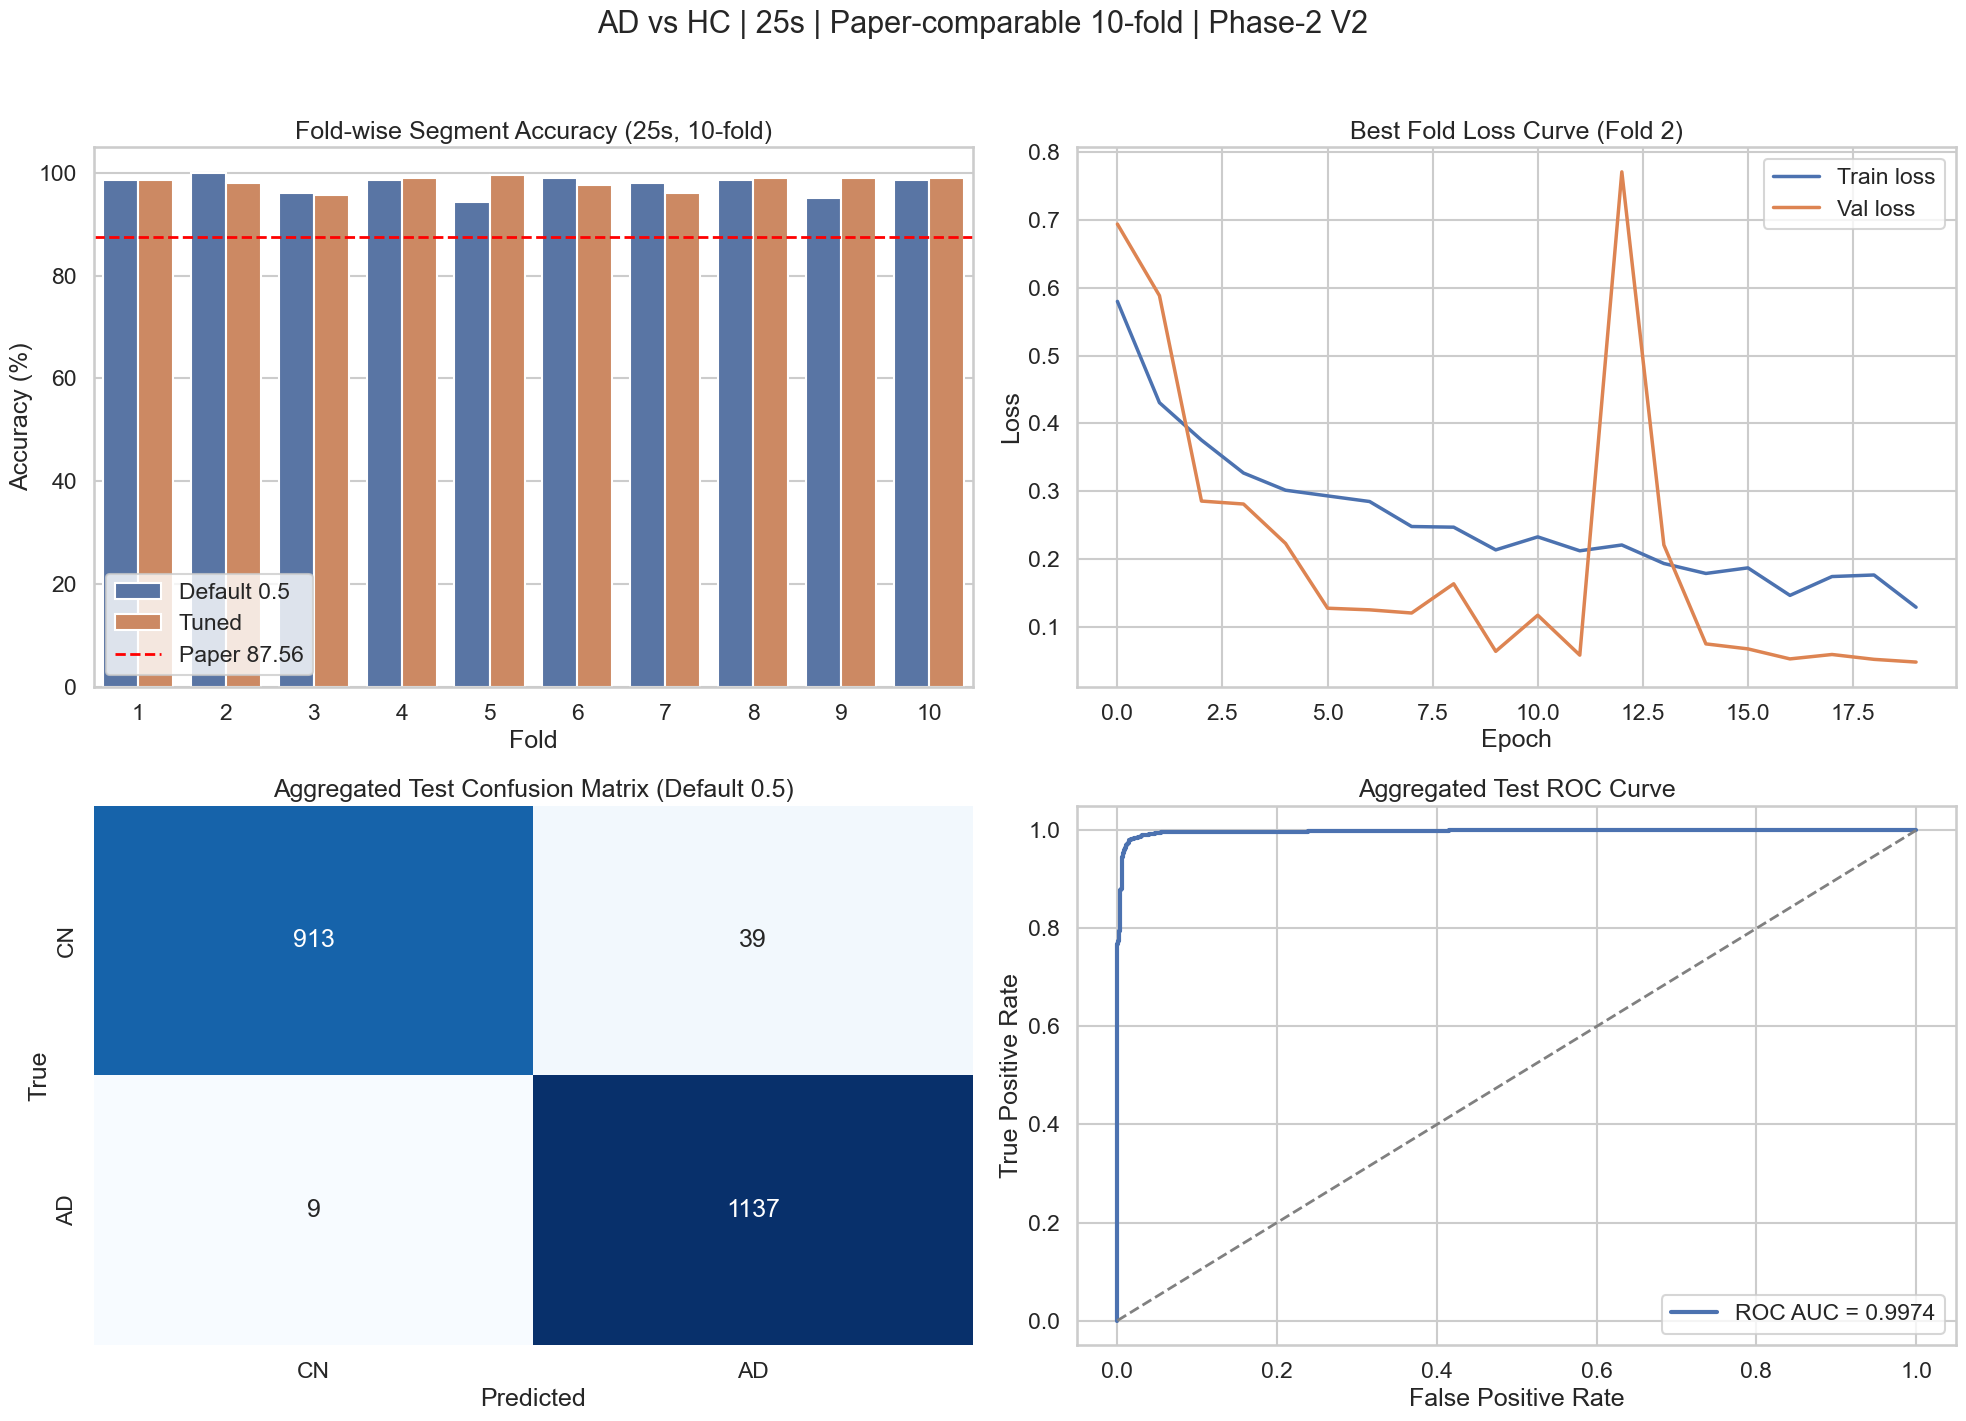

Saved figure: C:\Users\U\Desktop\Shoili\eeg_ad_hc_rebuild\phase2_clean_25s_paper10fold_batch8\beautiful_summary_figure.png


In [12]:
sns.set_theme(style="whitegrid", context="talk")

fold_df = pd.read_csv(FOLD_METRICS_CSV)
pred_df = pd.read_csv(SEGMENT_PREDS_CSV)

# aggregated confusion matrix and ROC
y_true_all = pred_df["y_true"].to_numpy().astype(int)
prob_all = pred_df["prob_disease"].to_numpy().astype(float)
pred_all = pred_df["pred_default_0_5"].to_numpy().astype(int)

cm = confusion_matrix(y_true_all, pred_all, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fpr, tpr, _ = roc_curve(y_true_all, prob_all)
auc_all = roc_auc_score(y_true_all, prob_all)

# best fold history
best_fold = int(fold_df.loc[fold_df["default_accuracy"].idxmax(), "fold"])
history_path = RUN_DIR / f"fold_{best_fold:02d}_history.csv"
hist_df = pd.read_csv(history_path)

# 2x2 summary figure
fig, axes = plt.subplots(2, 2, figsize=(20, 14))

# --- panel 1: fold accuracies ---
acc_long = pd.DataFrame({
    "fold": np.concatenate([fold_df["fold"].values, fold_df["fold"].values]),
    "accuracy": np.concatenate([fold_df["default_accuracy"].values, fold_df["tuned_accuracy"].values]),
    "mode": ["Default 0.5"] * len(fold_df) + ["Tuned"] * len(fold_df),
})

sns.barplot(
    data=acc_long,
    x="fold",
    y="accuracy",
    hue="mode",
    ax=axes[0, 0]
)
axes[0, 0].axhline(87.56, ls="--", lw=2, color="red", label="Paper 87.56")
axes[0, 0].set_title("Fold-wise Segment Accuracy (25s, 10-fold)")
axes[0, 0].set_xlabel("Fold")
axes[0, 0].set_ylabel("Accuracy (%)")
axes[0, 0].legend()

# --- panel 2: best fold training history ---
axes[0, 1].plot(hist_df["epoch"], hist_df["loss"], label="Train loss", linewidth=2.5)
axes[0, 1].plot(hist_df["epoch"], hist_df["val_loss"], label="Val loss", linewidth=2.5)
axes[0, 1].set_title(f"Best Fold Loss Curve (Fold {best_fold})")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()

# --- panel 3: confusion matrix ---
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["CN", "AD"],
    yticklabels=["CN", "AD"],
    ax=axes[1, 0]
)
axes[1, 0].set_title("Aggregated Test Confusion Matrix (Default 0.5)")
axes[1, 0].set_xlabel("Predicted")
axes[1, 0].set_ylabel("True")

# --- panel 4: ROC curve ---
axes[1, 1].plot(fpr, tpr, linewidth=3, label=f"ROC AUC = {auc_all:.4f}")
axes[1, 1].plot([0, 1], [0, 1], linestyle="--", linewidth=2, color="gray")
axes[1, 1].set_title("Aggregated Test ROC Curve")
axes[1, 1].set_xlabel("False Positive Rate")
axes[1, 1].set_ylabel("True Positive Rate")
axes[1, 1].legend(loc="lower right")

plt.suptitle("AD vs HC | 25s | Paper-comparable 10-fold | Phase-2 V2", fontsize=22, y=1.02)
plt.tight_layout()

fig_path = RUN_DIR / "beautiful_summary_figure.png"
plt.savefig(fig_path, dpi=220, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

In [13]:
summary_df = pd.read_csv(RUN_DIR / "summary.csv")

main_summary = summary_df[summary_df["metric"].isin([
    "default_accuracy",
    "default_sensitivity",
    "default_specificity",
    "default_precision",
    "default_f1",
    "default_roc_auc",
    "fold_time_min",
])].copy()

secondary_summary = summary_df[summary_df["metric"].isin([
    "tuned_accuracy",
    "tuned_sensitivity",
    "tuned_specificity",
    "tuned_precision",
    "tuned_f1",
    "tuned_roc_auc",
    "best_threshold",
])].copy()

print("MAIN SUMMARY")
display(main_summary)

print("SECONDARY SUMMARY")
display(secondary_summary)

print("Paper target for 25s 10-fold segment accuracy: 87.56%")
print(" mean default accuracy:",
      float(main_summary.loc[main_summary["metric"] == "default_accuracy", "mean"].values[0]))

MAIN SUMMARY


,metric,mean,std,min,max
1,fold_time_min,11.319120,0.102265,11.244195,11.599006
2,default_accuracy,97.711324,1.837764,94.285714,100.000000
3,default_sensitivity,99.212815,0.872058,97.368421,100.000000
4,default_specificity,95.896930,4.452423,87.368421,100.000000
5,default_precision,96.804852,3.341522,90.551181,100.000000
6,default_f1,0.979592,0.015910,0.950413,1.000000
7,default_roc_auc,0.998472,0.001993,0.994966,1.000000


SECONDARY SUMMARY


,metric,mean,std,min,max
0,best_threshold,0.491000,0.345180,0.065000,0.950000
8,tuned_accuracy,98.189565,1.304403,95.714286,99.523810
9,tuned_sensitivity,99.214340,0.958822,97.391304,100.000000
10,tuned_specificity,96.955044,2.234500,93.684211,98.958333
11,tuned_precision,97.537531,1.785054,94.915254,99.137931
12,tuned_f1,0.983623,0.011729,0.961373,0.995671
13,tuned_roc_auc,0.998472,0.001993,0.994966,1.000000


Paper target for 25s 10-fold segment accuracy: 87.56%
 mean default accuracy: 97.71132376395532
